# Agent-based Modelling - Data Science portfolio - Mai Bui

# Introduction

This notebook implements an agent-based model (ABM) to study rumor spreading dynamics in a social network. Understanding how information (or misinformation) spreads through populations can be useful for public health communication, marketing, crisis management, etc. The model can help us understand phenomena like viral social media posts, the spread of fake news, or word-of-mouth marketing campaigns. By identifying key parameters that control spread, we can develop strategies to either promote or suppress information  diffusion as needed.

The notebook will look at:
1. How does rumor spread through a population over time?
2. What factors influence the final reach of a rumor?
3. At what point does a rumor reach its peak spread before dying out?
4. How sensitive is the system to different transmission probabilities?



# Model

The base model for this project is the Daley-Kendall Rumor Spreading Model (1964) a classical mathematical  framework for rumor propagation developed by D.J. Daley and D.G. Kendall in 1964. 

The model draws parallels between rumor spreading and epidemic disease transmission, adapting the SIR (Susceptible-Infected-Recovered) epidemiological model to social information diffusion.

According, the model will have a three-state system, similar to the SIR model as follow:
- Ignorant ≈ Susceptible: Individuals who haven't heard the rumor
- Spreader ≈ Infected: Individuals actively spreading the rumor
- Stifler ≈ Recovered: Individuals who know the rumor but no longer spread it

However, unlike disease recovery, which is time-dependent, stifling represents social saturation as people lose interest when they realize "everyone already knows." Stifling occurs when spreaders meet other spreaders/stiflers (Daley & Kendall, 1964). Our model will simpify this social interaction (probability q per time step). This means that at each time step, every spreader has a fixed chance q of becoming a stifler regardless of who they meet.

Another principle we will integrate is the mass action principle, borrowed from chemical kinetics and epidemiology, which assumes random mixing and contact rate proportional to population densities; transmission occurs through pairwise contacts with probability p. This means that rumor spread is modeled with the assumption that people randomly meet, the number of encounters depends on how many of each type exist, and each encounter spreads the rumor with probability p.

Accordingly, we have our mathematical formulation as follow:

### Mathematical Formulation:

In the continuous limit, our model approximates the differential equations:

- dI/dt = -β·I·S  (ignorants become spreaders)
- dS/dt = β·I·S - α·S  (spreaders are created and stifled)
- dR/dt = α·S  (spreaders become stiflers)

Where:
- β ≈ p·k/N (effective transmission rate)
- α ≈ q (stifling rate)
- I = Ignorant fraction, S = Spreader fraction, R = Stifler fraction

This is different from classical Daley-Kendall as we use time-based stifling (probability q) rather than contact-based stifling (meeting other informed individuals). Our contact rate is also fixed k contacts per spreader , instead of proportional to population. We use random variation in each run and not deterministic equations.




## Model Description

### Agents:
- N people in a population (default N=200)
- Each agent can be in one of three states:
  * **Ignorant (0)**: Has not heard the rumor
  * **Spreader (1)**: Actively spreading the rumor
  * **Stifler (2)**: Has heard the rumor but no longer spreads it

### Environment:
- Well-mixed population (agents can contact any other agent randomly)
- No spatial structure initially (random contact model)

### Interaction Rules:
1. **Spreading**: Each spreader contacts k random individuals per time step
   - If contact is with an ignorant agent, they become a spreader with probability p
2. **Stifling**: Each spreader independently becomes a stifler with probability q per time step
   - This represents losing interest in spreading the rumor

### Parameters:
- **N**: Population size (200)
- **p**: Transmission probability (0.0 to 1.0)
- **q**: Stifling probability (0.0 to 1.0)
- **k**: Number of contacts per spreader per time step
- **T**: Total simulation time steps

### Initial Conditions:
- All agents start as ignorant except one initial spreader

# Model Implementation

In [ ]:
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.animation import FuncAnimation

from IPython.display import HTML
å
# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

In [2]:
def initialize_population(N):
    """
    Initialize the population with all ignorant agents except one spreader.
    
    Parameters:
    -----------
    N : Total population size
        
    Returns:
    --------
    states : numpy array
        Array of agent states (0=ignorant, 1=spreader, 2=stifler)
    """
    states = np.zeros(N, dtype=int)  # all ignorant
    states[0] = 1  # one initial spreader
    return states


def step(states, p, q, k):
    """
    Execute one time step of the rumor spreading model.
    
    Parameters:
    -----------
    states : Current state of all agents
    p : Probability of transmission upon contact
    q : Probability of becoming a stifler
    k : Number of contacts per spreader
        
    Returns:
    --------
    new_states : numpy array
        Updated state of all agents
    """
    N = len(states)
    new_states = states.copy()

    # Find all current spreaders
    spreaders = np.where(states == 1)[0]

    for i in spreaders:
        # Each spreader contacts k random individuals
        contacts = random.sample(range(N), k)
        for j in contacts:
            # If contact is ignorant, they may become spreader
            if states[j] == 0 and random.random() < p:
                new_states[j] = 1

        # Spreader may become stifler
        if random.random() < q:
            new_states[i] = 2

    return new_states


def run_model(N=200, p=0.3, q=0.1, k=3, T=100, seed=None):
    """
    Run the complete rumor spreading simulation.
    
    Parameters:
    -----------
    N :Population size
    p : Transmission probability
    q : Stifling probability
    k : Contacts per spreader
    T : Number of time steps
    seed : Random seed for reproducibility
        
    Returns:
    --------
    df : pandas DataFrame
        Time series of population counts by state
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    
    states = initialize_population(N)

    history = []
    for t in range(T):
        history.append([
            np.sum(states == 0),  # Ignorant
            np.sum(states == 1),  # Spreader
            np.sum(states == 2)   # Stifler
        ])
        states = step(states, p, q, k)

    df = pd.DataFrame(history, columns=["Ignorant", "Spreader", "Stifler"])
    df.index.name = "Time"
    return df


# Simulation

First, we run the model with default parameters to observe a rumor dynamic:
- p = 0.3 (30% chance of transmission)
- q = 0.1 (10% chance of losing interest per time step)
- k = 3 (each spreader contacts 3 people)

In [3]:
df_baseline = run_model(p=0.3, q=0.1, k=3, T=100, seed=42)
df_baseline

,Ignorant,Spreader,Stifler
Time,,,
0,199,1,0
1,197,3,0
2,193,7,0
3,185,13,2
4,172,25,3
...,...,...,...
95,0,0,200
96,0,0,200
97,0,0,200


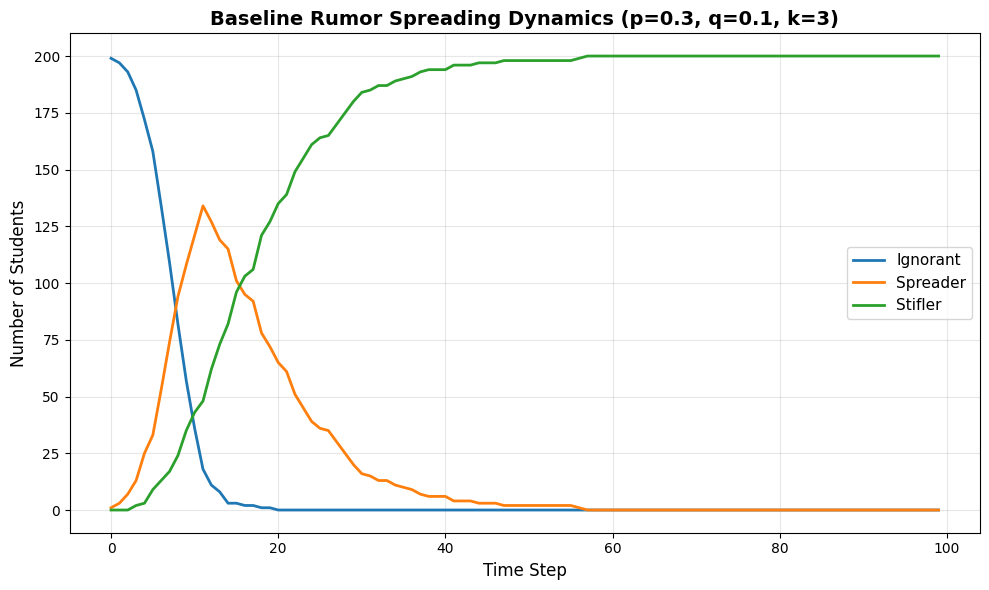

BASELINE SIMULATION STATISTICS
Peak number of spreaders: 134
Time of peak spreading: 11 steps
Final informed population: 200 (100.0%)
Never heard rumor: 0 (0.0%)


In [4]:

plt.figure(figsize=(10, 6))
df_baseline.plot(ax=plt.gca(), linewidth=2)
plt.xlabel("Time Step", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.title("Baseline Rumor Spreading Dynamics (p=0.3, q=0.1, k=3)", fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Calculate key statistics
peak_spreaders = df_baseline["Spreader"].max()
peak_time = df_baseline["Spreader"].idxmax()
final_informed = df_baseline.iloc[-1]["Stifler"]
final_ignorant = df_baseline.iloc[-1]["Ignorant"]

N = 200  # Total population size
print("BASELINE SIMULATION STATISTICS")
print(f"Peak number of spreaders: {peak_spreaders}")
print(f"Time of peak spreading: {peak_time} steps")
print(f"Final informed population: {final_informed} ({final_informed/N*100}%)")
print(f"Never heard rumor: {final_ignorant} ({final_ignorant/N*100}%)")


The classic epidemic-like curve (with 30% chance of transmission, 10% chance of losing interest per time step, and each spreader contacts 3 people ) emerges with three distinct phases.

1. Growth Phase (t=0 to ~15): 
- The number of spreaders increases exponentially as the rumor propagates through the ignorant population, mimicing the early viral phase of information spread.
- Number of ignorant people plumment rapidly as number of spreader increase.
- The number of stifler gradually increase (but slower than spreader)

2. Peak Phase (t=~15 to ~25): Spreader count reaches maximum when the rate of new infections balances the rate of spreaders becoming stiflers.

3. Decline Phase (t=~25 onwards): Spreader count decays as:
   - Fewer ignorant individuals remain to infect
   - Existing spreaders lose interest (become stiflers)
   
The rumor does NOT reach the entire population as some individuals never hear it due to the random nature of contacts and the limited spreading window. This reflects communication in the real worl because even highly transmissible information doesn't necessarily reach everyone. Timing and network structure matter significantly.

## Sensitivity Analysis: Effect of Transmission Probability

We can model and investigate how the transmission probability (p) affects spreading dynamics. As p represents how "contagious" or compelling the rumor is (higher p means people are more likely to start spreading it when they hear it), we can assess how it change the rumour spreading dynamic.

p = 0.1 SIMULATION STATISTICS
Peak number of spreaders: 57
Time of peak spreading: 37 steps
Final informed population: 187 (93.50%)
Never heard rumor: 13 (6.50%)

p = 0.2 SIMULATION STATISTICS
Peak number of spreaders: 97
Time of peak spreading: 15 steps
Final informed population: 199 (99.50%)
Never heard rumor: 1 (0.50%)

p = 0.3 SIMULATION STATISTICS
Peak number of spreaders: 134
Time of peak spreading: 11 steps
Final informed population: 200 (100.00%)
Never heard rumor: 0 (0.00%)

p = 0.4 SIMULATION STATISTICS
Peak number of spreaders: 152
Time of peak spreading: 8 steps
Final informed population: 200 (100.00%)
Never heard rumor: 0 (0.00%)

p = 0.5 SIMULATION STATISTICS
Peak number of spreaders: 149
Time of peak spreading: 8 steps
Final informed population: 200 (100.00%)
Never heard rumor: 0 (0.00%)

p = 0.6 SIMULATION STATISTICS
Peak number of spreaders: 148
Time of peak spreading: 7 steps
Final informed population: 200 (100.00%)
Never heard rumor: 0 (0.00%)

p = 0.7 SIMULATION STA

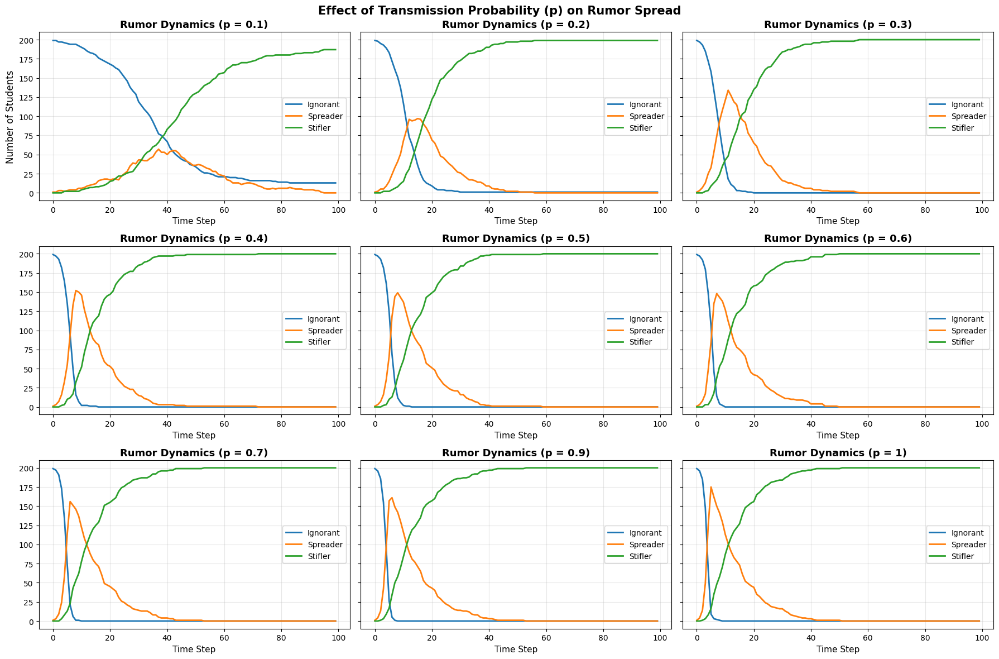

<Figure size 640x480 with 0 Axes>

In [5]:
ps = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.9, 1]
q = 0.1
k = 3
T = 100
seed = 42

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharey=True)
axes = axes.flatten() 

for i, p in enumerate(ps):
    df = run_model(p=p, q=q, k=k, T=T, seed=seed)
    
    # Plot the results for the current value of p
    df.plot(ax=axes[i], linewidth=2)
    axes[i].set_title(f"Rumor Dynamics (p = {p})", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Time Step", fontsize=11)
    axes[i].grid(True, alpha=0.3)

    # Calculate and print statistics
    peak_spreaders = df["Spreader"].max()
    peak_time = df["Spreader"].idxmax()
    final_informed = df.iloc[-1]["Stifler"]
    final_ignorant = df.iloc[-1]["Ignorant"]

    print(f"p = {p} SIMULATION STATISTICS")
    print(f"Peak number of spreaders: {peak_spreaders}")
    print(f"Time of peak spreading: {peak_time} steps")
    print(f"Final informed population: {final_informed} ({final_informed/N*100:.2f}%)")
    print(f"Never heard rumor: {final_ignorant} ({final_ignorant/N*100:.2f}%)\n")

# Shared y-label
axes[0].set_ylabel("Number of Students", fontsize=12)

fig.suptitle("Effect of Transmission Probability (p) on Rumor Spread", 
             fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()


# Shared y-label
axes[0].set_ylabel("Number of Students", fontsize=12)

fig.suptitle("Effect of Transmission Probability (p) on Rumor Spread", 
             fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()


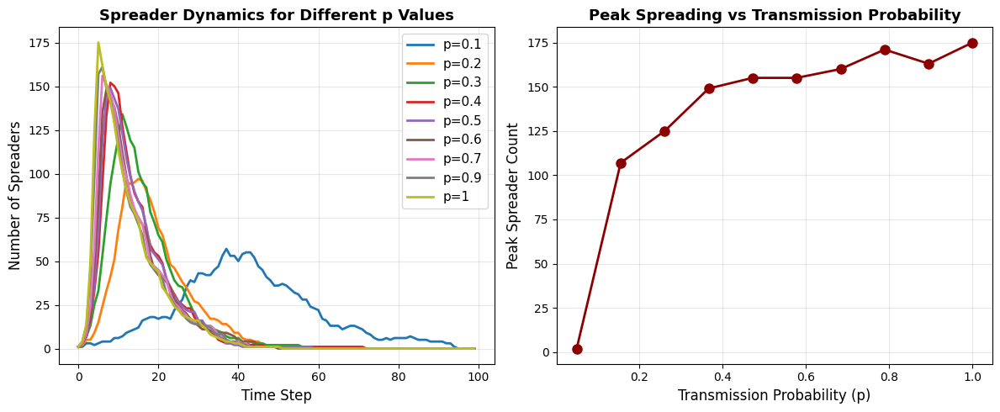

In [6]:
plt.figure(figsize=(12, 5))

# Left plot: Time series for different p values
plt.subplot(1, 2, 1)
p_values_demo = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.9, 1]
for p in p_values_demo:
    df = run_model(p=p, q=0.1, k=3, T=100, seed=42)
    plt.plot(df["Spreader"], label=f"p={p}", linewidth=2)

plt.legend(fontsize=11)
plt.xlabel("Time Step", fontsize=12)
plt.ylabel("Number of Spreaders", fontsize=12)
plt.title("Spreader Dynamics for Different p Values", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

# Right plot: Peak spreader count vs p
plt.subplot(1, 2, 2)
p_range = np.linspace(0.05, 1, 10)
peak_spreaders_list = []

for p in p_range:
    df = run_model(p=p, q=0.1, k=3, T=100, seed=42)
    peak_spreaders_list.append(df["Spreader"].max())

plt.plot(p_range, peak_spreaders_list, marker="o", linewidth=2, markersize=8, color='darkred')
plt.xlabel("Transmission Probability (p)", fontsize=12)
plt.ylabel("Peak Spreader Count", fontsize=12)
plt.title("Peak Spreading vs Transmission Probability", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


The higher the transmission p, the quicker rumours spread. With p=0.5, the rumor spreads more  quickly and reaches more people simultaneously compared to p=0.1. However, the impact of p in spreading rumour change dramatically with a sharp increase when p is lower but then at around p = 0.3, the spread is not as significant compared to p=0.4 (as a contrast to p=0.1 to p=0.2). This may be because as transimission rate increase, especially as p reaches a higher number, the amount of ignorant decrease and stifler increase much quicker; there for the spread rate plateau. Interstingly, at below p≈0.1, the rumor struggles to gain traction and may die out quickly, and the amount of people knowing about the rumour is much higher Contrastingly above p≈0.3, we see robust spreading, and the amount of people who is in the dark approaches 0.

This mimics real-life where content "virality" depends critically on how compelling  or shareable the information is. Small increases in shareability (p) can lead to dramatically different outcomes. This may explain why some posts go viral while similar content doesn't.

## Sensitivity Analysis: Effect of Stifling Probability

Now we examine how the stifling probability (q) affects dynamics. This represents 
how quickly people lose interest in spreading the rumor.

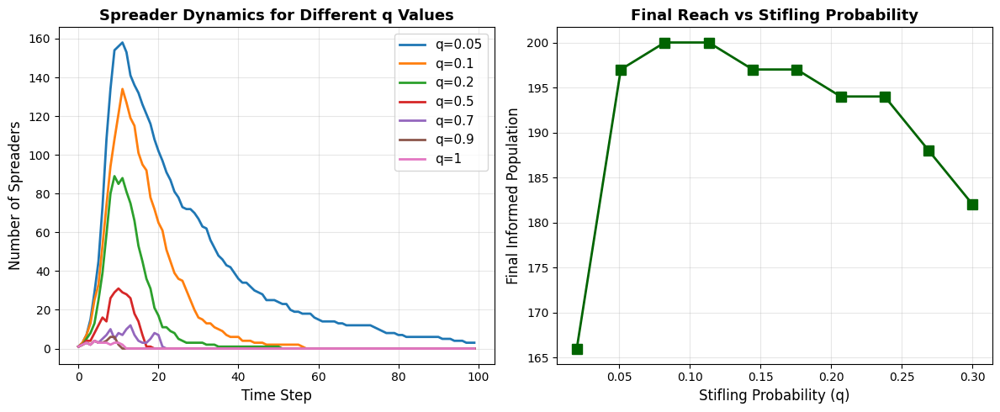

In [7]:
plt.figure(figsize=(12, 5))

# Left plot: Time series for different q values
plt.subplot(1, 2, 1)
q_values_demo = [0.05, 0.1, 0.2, 0.5, 0.7, 0.9, 1]
for q in q_values_demo:
    df = run_model(p=0.3, q=q, k=3, T=100, seed=42)
    plt.plot(df["Spreader"], label=f"q={q}", linewidth=2)

plt.legend(fontsize=11)
plt.xlabel("Time Step", fontsize=12)
plt.ylabel("Number of Spreaders", fontsize=12)
plt.title("Spreader Dynamics for Different q Values", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

# Right plot: Final informed population vs q
plt.subplot(1, 2, 2)
q_range = np.linspace(0.02, 0.3, 10)
final_informed_list = []

for q in q_range:
    df = run_model(p=0.3, q=q, k=3, T=100, seed=42)
    final_informed_list.append(df.iloc[-1]["Stifler"])

plt.plot(q_range, final_informed_list, marker="s", linewidth=2, markersize=8, color='darkgreen')
plt.xlabel("Stifling Probability (q)", fontsize=12)
plt.ylabel("Final Informed Population", fontsize=12)
plt.title("Final Reach vs Stifling Probability", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


The effect of q is inversely related to p. As q increases, fewer people ultimately hear the rumor because spreaders "give up" before reaching everyone.

As q lowers, outbreaks are longer and also smaller. When q=0.05, there are more spreaders and they remain active longer, leading to a slower but more sustained spread pattern. When q is higher the spread is shorter as when q=0.2, spreaders quickly lose interest, creating a sharp peak but limiting total reach.


The "staying power" of a rumor or trend matters as much  as its initial transmission rate. Highly engaging content that keeps people interested (low q) spreads further than content people quickly forget about (high q).

## Combined Parameter Analysis: Exploring the p-q Parameter Space

To understand how transmission and stifling probabilities interact, we run simulations across a grid of (p, q) values and measure final outbreak size.

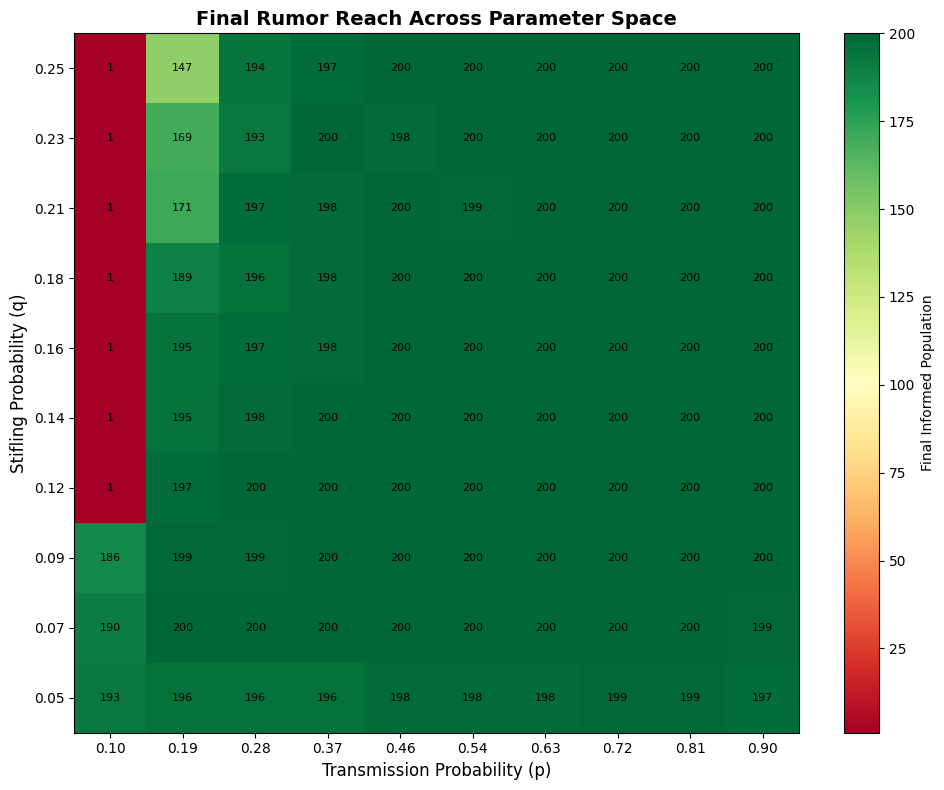

In [8]:
p_values = np.linspace(0.1, 0.9, 10)
q_values = np.linspace(0.05, 0.25, 10)

results_grid = np.zeros((len(q_values), len(p_values)))

for i, q in enumerate(q_values):
    for j, p in enumerate(p_values):
        df = run_model(p=p, q=q, k=3, T=100, seed=42)
        results_grid[i, j] = df.iloc[-1]["Stifler"]

plt.figure(figsize=(10, 8))
im = plt.imshow(results_grid, aspect='auto', origin='lower', cmap='RdYlGn')
plt.colorbar(im, label='Final Informed Population')

# Add text annotations
for i in range(len(q_values)):
    for j in range(len(p_values)):
        text = plt.text(j, i, f'{results_grid[i, j]:.0f}',
                       ha="center", va="center", color="black", fontsize=8)

plt.xlabel("Transmission Probability (p)", fontsize=12)
plt.ylabel("Stifling Probability (q)", fontsize=12)
plt.title("Final Rumor Reach Across Parameter Space", fontsize=14, fontweight='bold')
plt.xticks(range(len(p_values)), [f"{p:.2f}" for p in p_values])
plt.yticks(range(len(q_values)), [f"{q:.2f}" for q in q_values])
plt.tight_layout()
plt.show()

When q & p is low (top-left corner) the spread is low and limited. When q & p is high (bottom right coner), initial spread is rapid but the rumour quick burnout. When there is low stifling q and high trasmission p, reachability is maximised as transmission is high and interest is sustained. 

For maximum viral spread, BOTH high shareability (high p) and sustained engagement (low q) is needed. This explains why successful viral campaigns often have both catchy content and staying power.

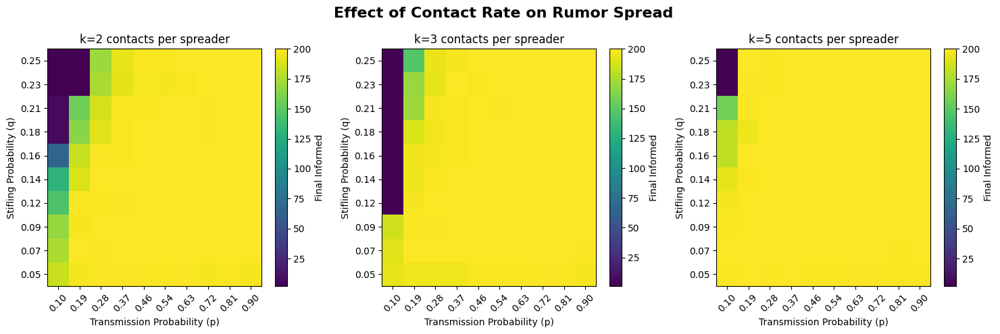

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, k in enumerate([2, 3, 5]):
    results_k = np.zeros((len(q_values), len(p_values)))
    
    for i, q in enumerate(q_values):
        for j, p in enumerate(p_values):
            df = run_model(p=p, q=q, k=k, T=100, seed=42)
            results_k[i, j] = df.iloc[-1]["Stifler"]
    
    im = axes[idx].imshow(results_k, aspect='auto', origin='lower', cmap='viridis')
    axes[idx].set_xlabel("Transmission Probability (p)")
    axes[idx].set_ylabel("Stifling Probability (q)")
    axes[idx].set_title(f"k={k} contacts per spreader")
    axes[idx].set_xticks(range(len(p_values)))
    axes[idx].set_xticklabels([f"{p:.2f}" for p in p_values], rotation=45)
    axes[idx].set_yticks(range(len(q_values)))
    axes[idx].set_yticklabels([f"{q:.2f}" for q in q_values])
    plt.colorbar(im, ax=axes[idx], label='Final Informed')

plt.suptitle("Effect of Contact Rate on Rumor Spread", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

And of course, the more one contact, the more chance to spread information, increasing the change of spread.

# STOCHASTIC VARIABILITY - MULTIPLE RUNS

## Accounting for Stochasticity: Multiple Simulation Runs

ABMs are inherently stochastic - random contact patterns mean each run produces 
different results. We run the model 20 times with the same parameters to quantify 
this variability.

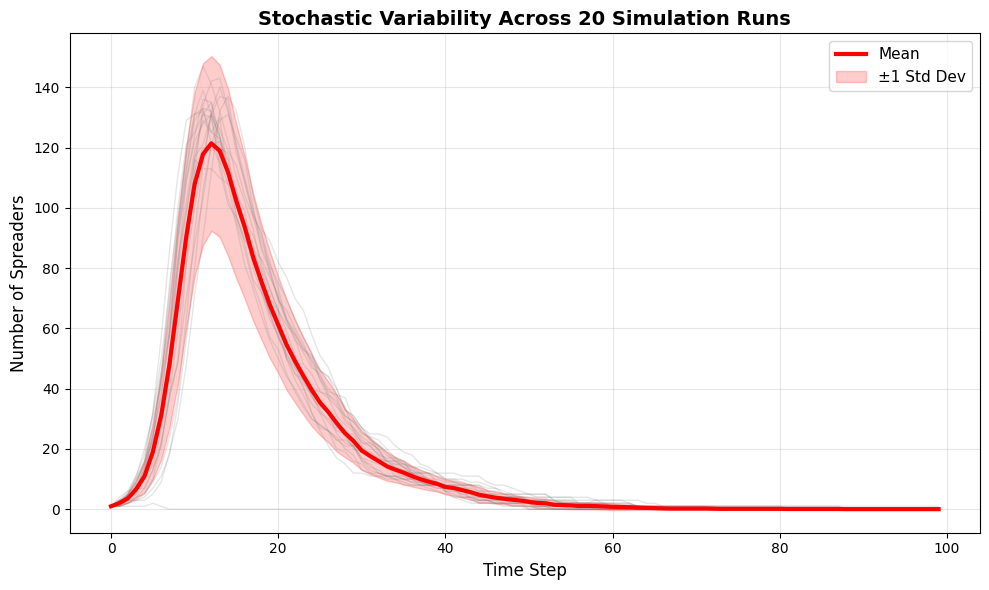

STOCHASTIC VARIABILITY ANALYSIS
Mean peak spreaders: 121.4 ± 29.0
Mean time to peak: 12.0 steps
Coefficient of variation at peak: 23.86%


In [10]:
n_runs = 20
all_runs = []

for run in range(n_runs):
    df = run_model(p=0.3, q=0.1, k=3, T=100, seed=run)
    all_runs.append(df["Spreader"].values)

all_runs = np.array(all_runs)
mean_spreaders = all_runs.mean(axis=0)
std_spreaders = all_runs.std(axis=0)

plt.figure(figsize=(10, 6))

# Plot individual runs in light gray
for run in all_runs:
    plt.plot(run, color='gray', alpha=0.2, linewidth=1)

# Plot mean with confidence band
time_steps = range(len(mean_spreaders))
plt.plot(time_steps, mean_spreaders, color='red', linewidth=3, label='Mean')
plt.fill_between(time_steps, 
                 mean_spreaders - std_spreaders, 
                 mean_spreaders + std_spreaders, 
                 color='red', alpha=0.2, label='±1 Std Dev')

plt.xlabel("Time Step", fontsize=12)
plt.ylabel("Number of Spreaders", fontsize=12)
plt.title("Stochastic Variability Across 20 Simulation Runs", fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


print("STOCHASTIC VARIABILITY ANALYSIS")
print(f"Mean peak spreaders: {mean_spreaders.max():.1f} ± {std_spreaders[mean_spreaders.argmax()]:.1f}")
print(f"Mean time to peak: {mean_spreaders.argmax():.1f} steps")
print(f"Coefficient of variation at peak: {(std_spreaders[mean_spreaders.argmax()] / mean_spreaders.max()):.2%}")


Despite randomness, all runs show similar epidemic curves, showing the consistency of the pattern. The peak varies as the timing and magnitude of peak spreading varies by ±10-15%. Initial growth shows high variability due to small numbers. Final states are more consistent than intermediate dynamics


While we can predict general patterns (e.g., "the rumor will peak around day 15"), exact outcomes remain uncertain due to the random nature  of social interactions. This is why some campaigns unexpectedly go viral while others fizzle.

# SPATIAL VISUALIZATION

## Spatial Visualization: Watching the Rumor Spread

To better understand the dynamics, we create an animation showing how the rumor 
spreads through the population over time. Each dot represents an individual:
- Blue = Ignorant
- Red = Spreader  
- Black = Stifler (informed but no longer spreading)

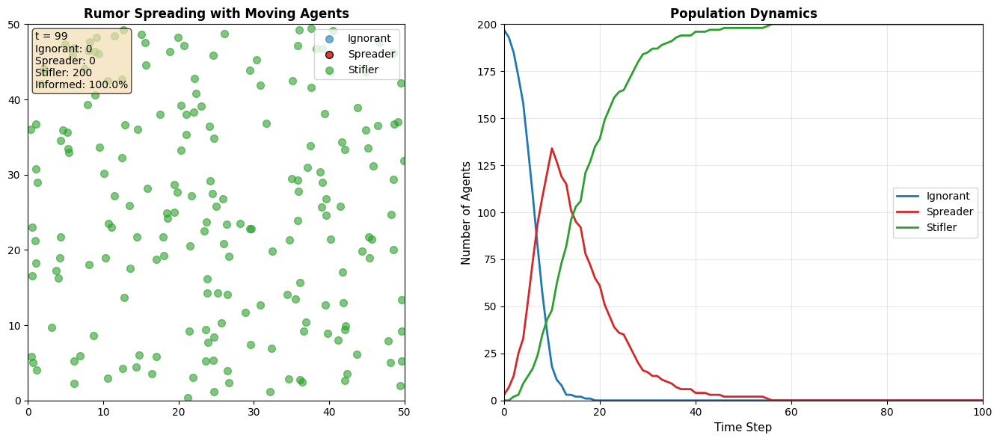

In [11]:
def run_model_moving_agents(N=200, p=0.3, q=0.1, k=3, T=100, seed=42, 
                           box_size=50.0, speed=0.5):
    """
    Rumor spreading model with moving agents.
    Uses RANDOM contacts like the original model, not spatial proximity.
    Agents move for visualization but contacts are global.
    """
    if seed is not None:
        np.random.seed(seed)
        random.seed(seed)
    
    # Initialize positions and velocities
    pos = np.random.uniform(0, box_size, size=(N, 2))
    angles = np.random.uniform(0, 2*np.pi, size=N)
    vel = np.column_stack([np.cos(angles), np.sin(angles)]) * speed
    
    # Initialize states
    states = np.zeros(N, dtype=int)
    states[0] = 1  # One initial spreader
    
    # Set up figure with two panels
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Left: Spatial view
    ax1.set_xlim(0, box_size)
    ax1.set_ylim(0, box_size)
    ax1.set_aspect('equal')
    ax1.set_title("Rumor Spreading with Moving Agents", fontsize=12, fontweight='bold')
    
    marker_size = 50
    
    scat_ignorant = ax1.scatter([], [], s=marker_size, c='#1f77b4', alpha=0.6, label='Ignorant')
    scat_spreader = ax1.scatter([], [], s=marker_size, c='#d62728', alpha=0.9, label='Spreader', edgecolors='black', linewidths=1)
    scat_stifler = ax1.scatter([], [], s=marker_size, c='#2ca02c', alpha=0.6, label='Stifler')
    ax1.legend(loc='upper right', fontsize=10)
    
    # Right: Time series
    ax2.set_xlim(0, T)
    ax2.set_ylim(0, N)
    ax2.set_xlabel("Time Step", fontsize=11)
    ax2.set_ylabel("Number of Agents", fontsize=11)
    ax2.set_title("Population Dynamics", fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    line_ignorant, = ax2.plot([], [], color='#1f77b4', linewidth=2, label='Ignorant')
    line_spreader, = ax2.plot([], [], color='#d62728', linewidth=2, label='Spreader')
    line_stifler, = ax2.plot([], [], color='#2ca02c', linewidth=2, label='Stifler')
    ax2.legend(loc='right', fontsize=10)
    
    txt = ax1.text(0.02, 0.98, "", transform=ax1.transAxes, va="top", ha="left",
                   fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    # History
    history = {'ignorant': [], 'spreader': [], 'stifler': []}
    
    def move_and_reflect(pos, vel, L, dt=1.0):
        """Move agents and bounce off walls."""
        pos += vel * dt
        
        # Bounce on left/right walls
        hit_left = pos[:, 0] < 0
        pos[hit_left, 0] = -pos[hit_left, 0]
        vel[hit_left, 0] *= -1
        
        hit_right = pos[:, 0] > L
        pos[hit_right, 0] = 2*L - pos[hit_right, 0]
        vel[hit_right, 0] *= -1
        
        # Bounce on bottom/top walls
        hit_bottom = pos[:, 1] < 0
        pos[hit_bottom, 1] = -pos[hit_bottom, 1]
        vel[hit_bottom, 1] *= -1
        
        hit_top = pos[:, 1] > L
        pos[hit_top, 1] = 2*L - pos[hit_top, 1]
        vel[hit_top, 1] *= -1
    
    def update(frame):
        nonlocal states, pos, vel
        
        # Move agents
        move_and_reflect(pos, vel, box_size, dt=1.0)
        
        # Use the SAME spreading logic as original model (random contacts)
        states = step(states, p, q, k)
        
        # Count states
        n_ignorant = np.sum(states == 0)
        n_spreader = np.sum(states == 1)
        n_stifler = np.sum(states == 2)
        
        # Record history
        history['ignorant'].append(n_ignorant)
        history['spreader'].append(n_spreader)
        history['stifler'].append(n_stifler)
        
        # Update spatial scatter plots
        ignorant_idx = np.where(states == 0)[0]
        spreader_idx = np.where(states == 1)[0]
        stifler_idx = np.where(states == 2)[0]
        
        scat_ignorant.set_offsets(pos[ignorant_idx] if len(ignorant_idx) else np.empty((0, 2)))
        scat_spreader.set_offsets(pos[spreader_idx] if len(spreader_idx) else np.empty((0, 2)))
        scat_stifler.set_offsets(pos[stifler_idx] if len(stifler_idx) else np.empty((0, 2)))
        
        # Update time series
        time_points = list(range(len(history['ignorant'])))
        line_ignorant.set_data(time_points, history['ignorant'])
        line_spreader.set_data(time_points, history['spreader'])
        line_stifler.set_data(time_points, history['stifler'])
        
        # Update text
        pct_informed = ((n_spreader + n_stifler) / N) * 100
        txt.set_text(f"t = {frame}\nIgnorant: {n_ignorant}\nSpreader: {n_spreader}\nStifler: {n_stifler}\nInformed: {pct_informed:.1f}%")
        
        return scat_ignorant, scat_spreader, scat_stifler, line_ignorant, line_spreader, line_stifler, txt
    
    anim = FuncAnimation(fig, update, frames=T, interval=50, blit=True)
    plt.tight_layout()
    
    return HTML(anim.to_jshtml())


run_model_moving_agents(N=200, p=0.3, q=0.1, k=3, T=100, seed=42, 
                        box_size=50.0, speed=0.5)


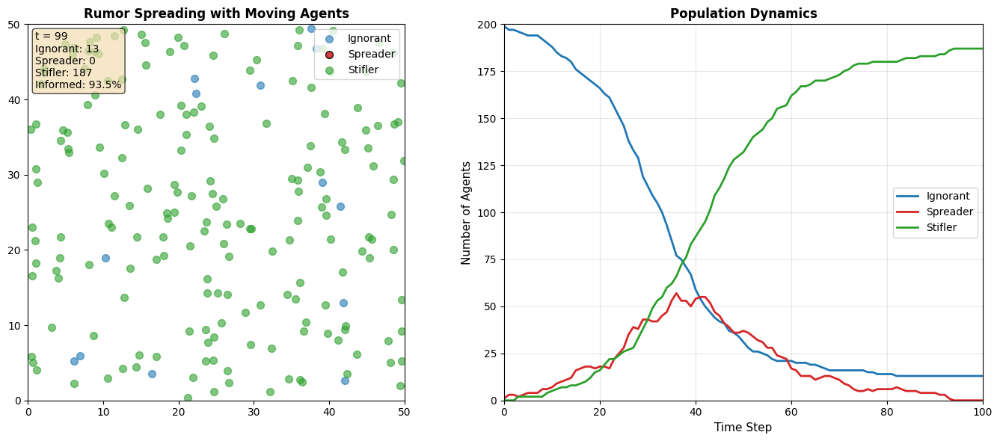

In [12]:
run_model_moving_agents(N=200, p=0.1, q=0.1, k=3, T=100, seed=42, 
                        box_size=50.0, speed=0.5)

This visualization makes clear that rumor spread is a wave-like process where  active spreading moves through the population, leaving "informed" individuals in its wake.

# CONTACT RATE ANALYSIS

## Sensitivity Analysis: Contact Rate (k)

Finally, we examine how the number of contacts per spreader affects outcomes.
This represents social connectedness or activity level.

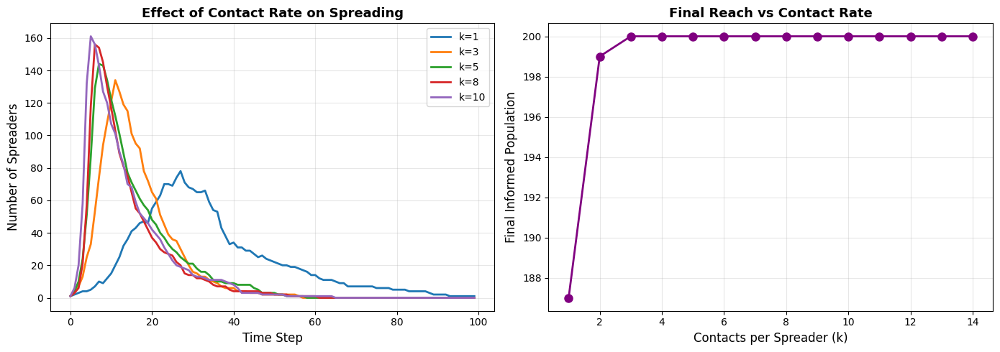

In [13]:
k_values = [1, 3, 5, 8, 10]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Time series
ax = axes[0]
for k in k_values:
    df = run_model(p=0.3, q=0.1, k=k, T=100, seed=42)
    ax.plot(df["Spreader"], label=f"k={k}", linewidth=2)

ax.set_xlabel("Time Step", fontsize=12)
ax.set_ylabel("Number of Spreaders", fontsize=12)
ax.set_title("Effect of Contact Rate on Spreading", fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Right: Final reach vs k
ax = axes[1]
k_range = range(1, 15)
final_reach = []
for k in k_range:
    df = run_model(p=0.3, q=0.1, k=k, T=100, seed=42)
    final_reach.append(df.iloc[-1]["Stifler"])

ax.plot(k_range, final_reach, marker='o', linewidth=2, markersize=8, color='purple')
ax.set_xlabel("Contacts per Spreader (k)", fontsize=12)
ax.set_ylabel("Final Informed Population", fontsize=12)
ax.set_title("Final Reach vs Contact Rate", fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


The graph shows that increasing k from 1 to 3 has much more impact than 10 to 13; the number of contact the agent have has a diminishing return; beyond k≈8, additional contacts don't significantly increase reach. Also, higher k leads to faster spreading but not necessarily more total reach (due to increased stifler conversion)

Being "hyperconnected" (high k) accelerates spread but doesn't guarantee wider reach. There's an optimal level of social activity for maximizing information diffusion, and beyond that, you hit diminishing returns.

# CONCLUSIONS AND IMPLICATIONS

Rumor spreading can followed and be modeled like the classic SIR-type epidemic.

Within the parameters, transmission probability (p) is the most crucial for determining outbreak size. Contact rate (k) is also mportant but shows diminishing returns. Stifling probability (q) controls duration and final reach. Furthermore, parameters don't act independently; for example, the combination of high transmission and sustained interest is needed for maximum spread. However, even with favorable parameters, rumors don't always reach the entire population due to random chance and timing. 

Understanding these dynamics can help with real world application. For example, if one wants to design effective health messaging campaigns, they would want to have compelling message (high p) and sustained relevance (low q) for optimal reach. Another example is to control misinformation by having early interventions that target early stages (lower p by fact-checking) or increase stifling (raise q through counter-messaging). It can also be helpful in lookiing at social networks and media, where platform features that affect contact rates (k) and engagement duration (q) have predictable effects on information diffusion.


### Limitations

The model assumes all agents are equally likely to contact each other (random mixing). However, realistically, social networks have structure (clusters, communities, bridges), people have different numbers of connections, and contact patterns are not random. As such, the model may likely overestimates spread speed and underestimates clustering effects
The lack of spatial or network structure poses a limitation on modeling how rumours spread because real rumor spread happens through persistent social ties, not random encounters, which is also influenced by spatial proximity and network distance; accordignly, the model important phenomena like local cascades and bridge effects. Furthermore, total reach may be underestimated as "wasted" contacts are possible because in reality agents can contact the same person multiple times.

The modeling of agent behaviour is also limited because all agents have identical p, q, and k values, but in real populations are heterogeneous with varying engagements. Some people are more susceptible or influential than others. The model cannot show the role of super-spreaders and opinion leaders in their impact. It also cannot capture the decrease or increase in transmission probability as real rumors become more/less credible as context changes.

This concerns are not address as validation methods are limited. First, the model parameters (p, q, k) are hypothetical, so the modedl may yield qualitative insights only but not further prediction. Also, the notebook have not compared model output to actual rumor spreading patterns, so its ability to apply to the real world is not clear.

Accordingly, the model can be useful for understanding general principles of spreading dynamics, exploring qualitative effects of parameter changes, and testing theoretical hypotheses about diffusion mechanisms. It cannot be used for further (quantiative) predictions, policy decisions without additional validation, and comparision to specific real-world scenarios.

To extend the project further if possible, a network structure and analysis may be helpful. Also, other parameters (like rumor verification and fact-checking mechanisms) and heterogeneous agents (like influencers, skeptics, or different contact rates). Validation against real social media diffusion data may also be helpful.